# Laboratorium 5 — Wpływ korpusu na tokenizację BPE i embeddingi Word2Vec
**Przedmiot:** Uczenie głębokie w systemach rozpoznawania i przetwarzania mowy  
**Autor:** Oskar Pietrzak  
**Data:** 18.11.2026

Własny korpus: 60 różnych zdań, słowo wieloznaczne **mysz** (zwierzę / urządzenie).
Notebook zawiera wykonane eksperymenty, tabele, PCA i demonstrację uwagi.

## 1. Biblioteki

In [1]:
%pip -q install tokenizers==0.23.3 gensim==4.4.0 scikit-learn==1.8.0 matplotlib pandas numpy

In [2]:
import re
from itertools import combinations
from zlib import crc32

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gensim.models import Word2Vec
from IPython.display import display
from sklearn.decomposition import PCA
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

np.random.seed(0)

## 2. Własny korpus i próbka form

Źródło: zdania przygotowane na potrzeby ćwiczenia, bez zewnętrznych tekstów.
Pule Z i U zawierają po 20 zdań; każde zawiera dokładnie jedno wystąpienie formy
„mysz”. Pula N zawiera 20 zdań bez tej formy, w tym konteksty obu tematów.
Normalizacja w obu eksperymentach: małe litery, wydzielenie pełnych słów
wyrażeniem regularnym (bez interpunkcji), zachowanie polskich znaków,
bez lematyzacji i usuwania słów funkcyjnych. Nie powielano korpusu.

In [3]:
ZWIERZE = [
    'Mysz chowa ziarno, a kot pilnuje wejścia do nory.',
    'Mysz odwiedza ogród, w którym pies znajduje ziarno.',
    'Mała mysz poznaje zapach, a klatka chroni jej gniazdo.',
    'Mysz szuka ziarna, gdy kot i pies odpoczywają obok.',
    'Mysz niesie ziarno, a nora zapewnia bezpieczne schronienie.',
    'Ciekawska mysz obserwuje, jak kot opuszcza ogród.',
    'Mysz słyszy hałas, gdy pies obchodzi ogród.',
    'Mysz znajduje ziarno, zanim kot zauważy jej ślady.',
    'Mysz odpoczywa, a klatka stoi przy oknie.',
    'Mysz wybiera schronienie, którym jest niewielka nora.',
    'Mysz zbiera ziarno, podczas gdy pies śpi przy drzwiach.',
    'Mysz rozpoznaje zapach, a kot szuka jej w ogrodzie.',
    'Mysz porusza wąsami i bada wejście do nory.',
    'Mysz buduje gniazdo z suchej trawy.',
    'Mysz zjada ziarno pozostawione przez opiekuna.',
    'Nocą mysz opuszcza gniazdo i odwiedza ogród.',
    'Mysz wspina się po gałęzi, którą obwąchuje pies.',
    'Mysz wraca do schronienia, a kot zostaje przy płocie.',
    'Mysz pije wodę, kiedy opiekun sprawdza gniazdo.',
    'Mysz odpoczywa w ściółce, a klatka wymaga sprzątania.',
]

URZADZENIE = [
    'Mysz przesuwa kursor, a komputer wyświetla ekran programu.',
    'Mysz ma przycisk i kabel, który łączy komputer.',
    'Mysz wskazuje ikonę, a ekran pokazuje kursor i przycisk.',
    'Mysz otrzymuje kabel, zanim komputer uruchomi ekran.',
    'Mysz przesuwa kursor, gdy użytkownik naciska przycisk.',
    'Mysz obsługuje komputer, a ekran pokazuje otwarte okno.',
    'Mysz ma przycisk, którym użytkownik zaznacza tekst.',
    'Mysz porusza kursor, a kabel pozostaje na biurku.',
    'Mysz uruchamia przycisk, który komputer wyświetla w programie.',
    'Mysz otrzymuje nowy kabel, a ekran pokazuje pulpit.',
    'Mysz wybiera ikonę, gdy komputer odświeża ekran.',
    'Mysz przesuwa kursor, a użytkownik sprawdza przycisk programu.',
    'Mysz leży na podkładce obok klawiatury.',
    'Mysz przewija dokument otwarty w edytorze.',
    'Mysz wysyła sygnał, który komputer odbiera przez kabel.',
    'Mysz umożliwia rysowanie prostych figur na ekranie.',
    'Mysz wymaga sterownika do obsługi dodatkowych funkcji.',
    'Mysz pomaga zaznaczać tekst i otwierać menu.',
    'Mysz zmienia czułość po naciśnięciu bocznego przycisku.',
    'Mysz działa bezprzewodowo, gdy komputer rozpoznaje odbiornik.',
]

NEUTRALNE = [
    'Kot oraz pies obserwują ogród i puste gniazdo.',
    'Nora kryje ziarno, a klatka stoi w cichym pokoju.',
    'Kot omija miejsce, gdzie pies znalazł ziarno.',
    'Klatka jest czysta, a nora pozostaje ukryta pod krzewem.',
    'Pies pilnuje ogrodu, kiedy kot odpoczywa przy oknie.',
    'Opiekun zajmuje się kotami oraz psami i sprząta gniazdo.',
    'Komputer pokazuje ekran, kursor oraz przycisk aplikacji.',
    'Kabel łączy komputer, a ekran wyświetla nowy dokument.',
    'Kursor wskazuje przycisk, który otwiera menu programu.',
    'Komputer otrzymuje nowy kabel i dodatkowy ekran.',
    'Przycisk przesuwa kursor do następnego pola formularza.',
    'Program działa na komputerach wyposażonych w nowe monitory.',
    'Student czyta książkę podczas podróży pociągiem.',
    'Studenci piszą raport i opisują wyniki doświadczenia.',
    'Badacz porównuje modele oraz analizuje zebrane dane.',
    'Biblioteka udostępnia książki o historii oraz geografii.',
    'Nauczyciel omawia zadanie z nowymi studentami.',
    'Wieczorem autobus zatrzymuje się przed uczelnią.',
    'Laboratorium jest otwarte, ale pracownia pozostaje zamknięta.',
    'Wyniki zapisano w tabelach oraz na kolorowych wykresach.',
]

def slowa(tekst):
    return re.findall(r'[^\W\d_]+', tekst.lower())

KORPUS = ZWIERZE + URZADZENIE + NEUTRALNE
tokeny_korpusu = [slowa(s) for s in KORPUS]
tekst_bpe = [' '.join(s) for s in tokeny_korpusu]
slownik_korpusu = {w for s in tokeny_korpusu for w in s}
assert len(KORPUS) == len(set(KORPUS)) == 60
assert all(slowa(s).count('mysz') == 1 for s in ZWIERZE + URZADZENIE)
assert all('mysz' not in slowa(s) for s in NEUTRALNE)
display(pd.DataFrame({
    'Pula': ['Z — zwierzę', 'U — urządzenie', 'N — bez słowa mysz'],
    'Zdania': [len(ZWIERZE), len(URZADZENIE), len(NEUTRALNE)],
    'Wystąpienia mysz': [20, 20, 0],
}))

pary = pd.DataFrame({
    'Widziana': ['mysz', 'kot', 'komputer', 'ekran', 'klatka', 'kursor'],
    'Niewidziana': ['myszami', 'kotem', 'komputerami', 'ekranami', 'klatkami', 'kursorami'],
})
pary['Widziana w korpusie'] = pary['Widziana'].isin(slownik_korpusu)
pary['Niewidziana w korpusie'] = pary['Niewidziana'].isin(slownik_korpusu)
assert pary['Widziana w korpusie'].all()
assert not pary['Niewidziana w korpusie'].any()
display(pary)

,Pula,Zdania,Wystąpienia mysz
0,Z — zwierzę,20,20
1,U — urządzenie,20,20
2,N — bez słowa mysz,20,0


,Widziana,Niewidziana,Widziana w korpusie,Niewidziana w korpusie
0,mysz,myszami,True,False
1,kot,kotem,True,False
2,komputer,komputerami,True,False
3,ekran,ekranami,True,False
4,klatka,klatkami,True,False
5,kursor,kursorami,True,False


## 3. Porównanie tokenizacji BPE

**Hipoteza przed treningiem:** większy słownik pozwoli łączyć dłuższe fragmenty,
więc średnia liczba tokenów powinna maleć dla form widzianych i niewidzianych.
Spodziewany spadek dla form niewidzianych może być słabszy, ponieważ ich pełne
postacie nie pojawiły się w treningu. BPE nie musi odtwarzać granic morfemów.

Każdy tokenizer uczy się na tych samych 60 zdaniach. Zmieniamy tylko `vocab_size`:
100, 200, 400. Pozostałe parametry: `min_frequency=1`, `[UNK]`, `Whitespace`.
Średnie są nieważone: każdą z sześciu form w danej grupie kodujemy osobno jeden raz.

In [4]:
tokenizery = {}
wyniki_bpe = []
podzialy_bpe = []
for limit in [100, 200, 400]:
    tok = Tokenizer(models.BPE(unk_token='[UNK]'))
    tok.pre_tokenizer = pre_tokenizers.Whitespace()
    trener = trainers.BpeTrainer(
        vocab_size=limit, min_frequency=1, special_tokens=['[UNK]']
    )
    tok.train_from_iterator(tekst_bpe, trainer=trener)
    tokenizery[limit] = tok
    wiersz = {'Limit': limit, 'Faktyczny rozmiar': tok.get_vocab_size()}
    for grupa in ['Widziana', 'Niewidziana']:
        podzialy = [tok.encode(w).tokens for w in pary[grupa]]
        wiersz[f'{grupa}: średnia'] = np.mean([len(t) for t in podzialy])
        wiersz[f'{grupa}: formy z UNK'] = sum('[UNK]' in t for t in podzialy)
        for forma, podzial in zip(pary[grupa], podzialy):
            podzialy_bpe.append({
                'Limit': limit, 'Grupa': grupa, 'Forma': forma,
                'Podział': ' | '.join(podzial), 'Tokeny': len(podzial),
            })
    wyniki_bpe.append(wiersz)
tabela_bpe = pd.DataFrame(wyniki_bpe)
tabela_podzialow = pd.DataFrame(podzialy_bpe)
assert len(set(tabela_bpe['Faktyczny rozmiar'])) == 3
display(tabela_bpe.round(3))
display(tabela_podzialow)

,Limit,Faktyczny rozmiar,Widziana: średnia,Widziana: formy z UNK,Niewidziana: średnia,Niewidziana: formy z UNK
0,100,100,1.5,0,4.500,0
1,200,200,1.0,0,3.000,0
2,400,400,1.0,0,2.833,0


,Limit,Grupa,Forma,Podział,Tokeny
0,100,Widziana,mysz,mysz,1
1,100,Widziana,kot,kot,1
2,100,Widziana,komputer,komputer,1
3,100,Widziana,ekran,ekran,1
4,100,Widziana,klatka,k | la | t | ka,4
5,100,Widziana,kursor,kursor,1
6,100,Niewidziana,myszami,mysz | a | m | i,4
7,100,Niewidziana,kotem,ko | te | m,3
8,100,Niewidziana,komputerami,kompute | ra | m | i,4
9,100,Niewidziana,ekranami,ek | ra | na | m | i,5


In [5]:
przyklady_bpe = tabela_podzialow[
    tabela_podzialow['Forma'].isin(['myszami', 'komputerami'])
][['Limit', 'Forma', 'Podział']]
display(przyklady_bpe)

pochodzenie_fragmentow = []
for limit, tok in tokenizery.items():
    for forma in ['myszami', 'komputerami']:
        for fragment in tok.encode(forma).tokens:
            przyklady = sorted(w for w in slownik_korpusu if fragment in w)
            pochodzenie_fragmentow.append({
                'Limit': limit, 'Forma': forma, 'Fragment': fragment,
                'Formy treningowe (do 3)': ', '.join(przyklady[:3]),
            })
display(pd.DataFrame(pochodzenie_fragmentow))

,Limit,Forma,Podział
6,100,myszami,mysz | a | m | i
8,100,komputerami,kompute | ra | m | i
18,200,myszami,mysz | a | mi
20,200,komputerami,kompute | ra | mi
30,400,myszami,mysz | ami
32,400,komputerami,kompute | ra | mi


,Limit,Forma,Fragment,Formy treningowe (do 3)
0,100,myszami,mysz,mysz
1,100,myszami,a,"a, ale, analizuje"
2,100,myszami,m,"cichym, dokument, formularza"
3,100,myszami,i,"analizuje, aplikacji, bezpieczne"
4,100,komputerami,kompute,"komputer, komputerach"
5,100,komputerami,ra,"ekran, ekranie, geografii"
6,100,komputerami,m,"cichym, dokument, formularza"
7,100,komputerami,i,"analizuje, aplikacji, bezpieczne"
8,200,myszami,mysz,mysz
9,200,myszami,a,"a, ale, analizuje"


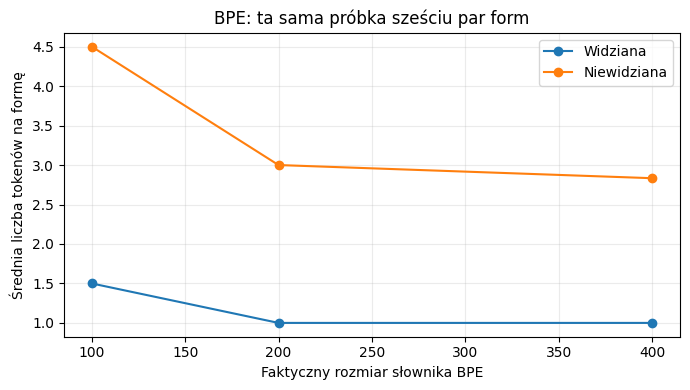

In [6]:
plt.figure(figsize=(7, 4))
for grupa in ['Widziana', 'Niewidziana']:
    plt.plot(tabela_bpe['Faktyczny rozmiar'], tabela_bpe[f'{grupa}: średnia'],
             marker='o', label=grupa)
plt.xlabel('Faktyczny rozmiar słownika BPE')
plt.ylabel('Średnia liczba tokenów na formę')
plt.title('BPE: ta sama próbka sześciu par form')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Word2Vec: zmiana proporcji znaczeń

Wariant A: pierwszych 12 zdań Z + pierwsze 4 U + wszystkie 20 N.
Wariant B: pierwsze 4 Z + pierwszych 12 U + te same 20 N.
Każdy wariant ma 36 zdań i 16 wystąpień „mysz”; liczba pozostałych słów może się różnić.
To kontrolowana zmiana kontekstów; nie izoluje ona wpływu samej częstości słów.

**Wybór grup przed treningiem i oglądaniem PCA:**
- Zwierzęta: `kot`, `pies`, `nora`, `ziarno`, `klatka` — zwierzęta, pokarm i schronienia.
- Technologia: `komputer`, `ekran`, `kursor`, `przycisk`, `kabel` — sprzęt i obsługa interfejsu.

Parametry obu modeli: Skip-gram, 50 wymiarów, `window=3`, `min_count=2`,
`epochs=400`, `seed=0`, `workers=1`, `sample=0`, `negative=5`,
`alpha=0.025`, `min_alpha=0.0001`; stabilne haszowanie `crc32`. Wyłączenie subsamplingu zachowuje
nieliczne wystąpienia słów. Nie używamy tokenizacji BPE do Word2Vec.

In [7]:
grupa_z = ['kot', 'pies', 'nora', 'ziarno', 'klatka']
grupa_u = ['komputer', 'ekran', 'kursor', 'przycisk', 'kabel']
warianty = {
    'A': ZWIERZE[:12] + URZADZENIE[:4] + NEUTRALNE,
    'B': ZWIERZE[:4] + URZADZENIE[:12] + NEUTRALNE,
}
zdania_w2v = {nazwa: [slowa(s) for s in zdania]
              for nazwa, zdania in warianty.items()}
assert all(len(s) == 36 for s in zdania_w2v.values())
assert all(sum(s.count('mysz') for s in zdania) == 16
           for zdania in zdania_w2v.values())

modele = {}
for nazwa, zdania in zdania_w2v.items():
    modele[nazwa] = Word2Vec(
        sentences=zdania, vector_size=50, window=3, min_count=2,
        sg=1, epochs=400, seed=0, workers=1, sample=0, negative=5,
        alpha=0.025, min_alpha=0.0001,
        hashfxn=lambda word: crc32(word.encode('utf-8')),
    )
liczebnosci = pd.DataFrame([
    {'Słowo': w, **{n: sum(s.count(w) for s in zdania_w2v[n]) for n in ['A', 'B']}}
    for w in grupa_z + grupa_u + ['mysz']
])
assert (liczebnosci['A'] >= 2).all()
assert all(w in modele['A'].wv for w in grupa_z + grupa_u)
display(liczebnosci)

sasiedzi = pd.DataFrame([
    {'Model': nazwa, 'Pozycja': i, 'Sąsiad': w, 'Cosinus': float(cos)}
    for nazwa, model in modele.items()
    for i, (w, cos) in enumerate(model.wv.most_similar('mysz', topn=5), 1)
])
display(sasiedzi.round(4))

slowa_rankingu = sorted(set(sasiedzi['Sąsiad']))
kontrola_rankingu = pd.DataFrame([
    {'Słowo': w, **{f'Wektor w {n}': w in modele[n].wv for n in ['A', 'B']},
     **{f'Wystąpienia w {n}': sum(s.count(w) for s in zdania_w2v[n])
        for n in ['A', 'B']},
     **{f'Cosinus z mysz w {n}': float(modele[n].wv.similarity('mysz', w))
        if w in modele[n].wv else np.nan for n in ['A', 'B']}}
    for w in slowa_rankingu
])
display(kontrola_rankingu.round(4))

,Słowo,A,B
0,kot,8,5
1,pies,7,5
2,nora,4,2
3,ziarno,7,4
4,klatka,4,3
5,komputer,6,9
6,ekran,6,9
7,kursor,5,8
8,przycisk,5,9
9,kabel,4,6


,Model,Pozycja,Sąsiad,Cosinus
0,A,1,jej,0.4724
1,A,2,do,0.4500
2,A,3,nora,0.4183
3,A,4,pilnuje,0.3682
4,A,5,nowy,0.3594
5,B,1,użytkownik,0.5434
6,B,2,pies,0.5149
7,B,3,łączy,0.4562
8,B,4,do,0.4505
9,B,5,wyświetla,0.3582


,Słowo,Wektor w A,Wektor w B,Wystąpienia w A,Wystąpienia w B,Cosinus z mysz w A,Cosinus z mysz w B
0,do,True,True,2,2,0.4500,0.4505
1,jej,True,False,3,1,0.4724,NaN
2,nora,True,True,4,2,0.4183,0.3416
3,nowy,True,True,2,3,0.3594,0.2908
4,pies,True,True,7,5,0.3515,0.5149
5,pilnuje,True,True,2,2,0.3682,0.2263
6,użytkownik,False,True,0,3,NaN,0.5434
7,wyświetla,True,True,2,3,0.0796,0.3582
8,łączy,True,True,2,2,0.2136,0.4562


Dodatkowo: sąsiedzi dwóch słów tematycznych w modelu A (łącznie z „mysz” analizujemy trzy słowa).

In [8]:
dodatkowi_sasiedzi = pd.DataFrame([
    {'Zapytanie': q, 'Sąsiad': w, 'Cosinus': float(cos)}
    for q in ['kot', 'komputer']
    for w, cos in modele['A'].wv.most_similar(q, topn=3)
])
display(dodatkowi_sasiedzi.round(4))

,Zapytanie,Sąsiad,Cosinus
0,kot,podczas,0.6479
1,kot,gniazdo,0.5331
2,kot,gdy,0.5077
3,komputer,nowy,0.6393
4,komputer,wyświetla,0.5997
5,komputer,wskazuje,0.5513


## 5. Jeden rzut PCA i podobieństwa w 50 wymiarach

PCA dopasowujemy raz do 11 surowych wektorów modelu A: dwóch ustalonych
grup po 5 słów oraz „mysz”. Średnie cosinusów obejmują po 10 różnych par
wewnątrz każdej grupy i 25 par między grupami; „mysz” nie wchodzi do tych średnich.

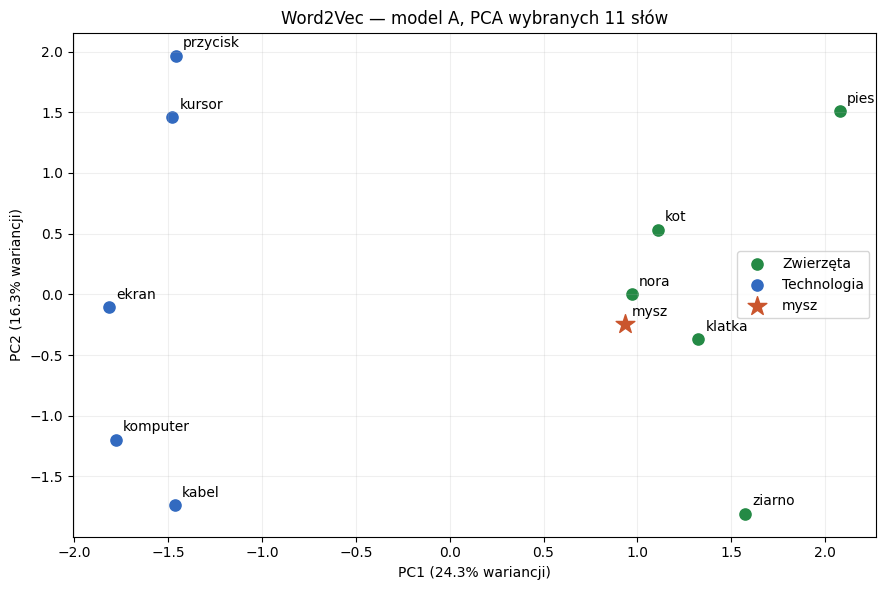

Wariancja wyjaśniona przez PC1 i PC2: 0.40572748


,Pary,Liczba par,Średni cosinus
0,Wewnątrz zwierząt,10,0.3217
1,Wewnątrz technologii,10,0.4358
2,Między grupami,25,0.1658


,Słowo 1,Słowo 2,Cosinus 50D,Odległość PCA 2D
0,komputer,ekran,0.5383,1.0930
1,kot,pies,0.4021,1.3769
2,kot,komputer,0.1548,3.3660


In [9]:
model = modele['A']
wybrane = grupa_z + grupa_u + ['mysz']
V = np.stack([model.wv[w] for w in wybrane])
pca = PCA(n_components=2, svd_solver='full')
XY = pca.fit_transform(V)

fig, ax = plt.subplots(figsize=(9, 6))
for indeksy, kolor, etykieta in [
    (range(5), '#248a45', 'Zwierzęta'),
    (range(5, 10), '#326ac0', 'Technologia'),
]:
    indeksy = list(indeksy)
    ax.scatter(XY[indeksy, 0], XY[indeksy, 1], c=kolor, s=65, label=etykieta)
ax.scatter(*XY[-1], c='#ca552d', s=200, marker='*', label='mysz')
for (x, y), w in zip(XY, wybrane):
    ax.annotate(w, (x, y), xytext=(5, 6), textcoords='offset points', fontsize=10)
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} wariancji)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} wariancji)')
ax.set_title('Word2Vec — model A, PCA wybranych 11 słów')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig('pca_lab_05.png', dpi=160, bbox_inches='tight')
plt.show()
print('Wariancja wyjaśniona przez PC1 i PC2:', pca.explained_variance_ratio_.sum())

pary_grup = {
    'Wewnątrz zwierząt': list(combinations(grupa_z, 2)),
    'Wewnątrz technologii': list(combinations(grupa_u, 2)),
    'Między grupami': [(a, b) for a in grupa_z for b in grupa_u],
}
cosinusy = pd.DataFrame([
    {'Pary': nazwa, 'Liczba par': len(pary),
     'Średni cosinus': np.mean([model.wv.similarity(a, b) for a, b in pary])}
    for nazwa, pary in pary_grup.items()
])
display(cosinusy.round(4))
przyklady_par = pd.DataFrame([
    {'Słowo 1': a, 'Słowo 2': b, 'Cosinus 50D': float(model.wv.similarity(a, b)),
     'Odległość PCA 2D': float(np.linalg.norm(XY[wybrane.index(a)] - XY[wybrane.index(b)]))}
    for a, b in [('komputer', 'ekran'), ('kot', 'pies'), ('kot', 'komputer')]
])
display(przyklady_par.round(4))

## 6. Demonstracja uwagi z notebooka ćwiczeniowego

Jedno zapytanie „mysz”; klucze i wartości to te same wektory Word2Vec modelu A.
Liczymy `softmax(K @ q / sqrt(50))` i ważoną sumę. To uproszczenie bez
uczonych projekcji Q/K/V; uwaga nie jest tu dowodem rozpoznawania znaczeń.

,Słowo,Waga uwagi
0,mysz,0.3135
1,przesuwa,0.0985
2,kursor,0.0947
3,a,0.0830
4,komputer,0.1312
5,wyświetla,0.0883
6,ekran,0.0891
7,programu,0.1017


Suma wag: 1.0 | Wymiar kontekstu: (50,)


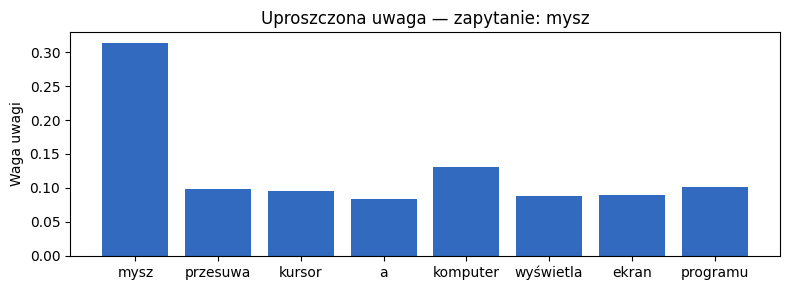

In [10]:
zdanie = slowa(URZADZENIE[0])
zdanie = [w for w in zdanie if w in model.wv]
K = np.stack([model.wv[w] for w in zdanie])
q = model.wv['mysz']
scores = K @ q / np.sqrt(K.shape[1])
wagi = np.exp(scores - scores.max())
wagi /= wagi.sum()
kontekst = wagi @ K
assert np.isclose(wagi.sum(), 1)
assert kontekst.shape == (50,)
display(pd.DataFrame({'Słowo': zdanie, 'Waga uwagi': wagi}).round(4))
print('Suma wag:', wagi.sum(), '| Wymiar kontekstu:', kontekst.shape)
plt.figure(figsize=(8, 3))
plt.bar(zdanie, wagi, color='#326ac0')
plt.ylabel('Waga uwagi')
plt.title('Uproszczona uwaga — zapytanie: mysz')
plt.tight_layout()
plt.show()

## 7. Analiza i wnioski

- BPE: średnia dla form widzianych wyniosła **1,50 → 1,00 → 1,00**,
  a dla niewidzianych **4,50 → 3,00 → 2,83**. Wszystkie trzy faktyczne
  słowniki są różne; żadna testowa forma nie zawierała `[UNK]`.
  Hipoteza jest wsparta na poziomie średnich, lecz nie każda forma się skraca:
  `kotem` ma zawsze 3 tokeny. `myszami` przy 400 dzieli się na `mysz | ami`,
  a `komputerami` pozostaje `kompute | ra | mi` — BPE nie jest analizą morfemową.
- Word2Vec: w A sąsiadami „mysz” są `jej`, `do`, `nora`, `pilnuje`, `nowy`;
  w B: `użytkownik`, `pies`, `łączy`, `do`, `wyświetla`. Konteksty technologiczne
  są widoczne w B, ale `pies` nadal zajmuje wysoką pozycję. Przy zaledwie
  16 wystąpieniach wieloznacznego słowa nie otrzymujemy czystego rozdzielenia znaczeń.
  „Mysz” ma jeden statyczny wektor w każdym modelu.
- `Jej` ma 3 wystąpienia w A i 1 w B, dlatego próg `min_count=2` usuwa je ze
  słownika B. `Nora`, `pilnuje` i `nowy` zachowują wektory w B, mimo spadku poza
  pierwszą piątkę. Z5 („Mysz niesie ziarno, a nora zapewnia bezpieczne schronienie”)
  pomaga wyjaśnić sąsiedztwo w A; U5 („Mysz przesuwa kursor, gdy użytkownik naciska
  przycisk”) wyjaśnia jeden z kontekstów w B.
- Na PCA grupy są rozdzielone głównie wzdłuż PC1. Średnie cosinusy w 50D:
  zwierzęta **0,3217**, technologia **0,4358**, między grupami **0,1658**.
  `komputer–ekran` ma cosinus **0,5383**, a `kot–komputer` **0,1548**;
  te pary wspierają obserwację tematycznych grup.
- Dwie składowe wyjaśniają **40,57%** wariancji wybranych 11 wektorów.
  Rzut traci informację, a odległości euklidesowe na PCA nie są cosinusami.
  Wnioski dotyczą małego, przygotowanego korpusu i jednego ziarna losowania.
